# Measure: o dado é confiável, e o que o processo entrega hoje?

**Projeto:** Saúde fiscal do Rio de Janeiro (Siconfi, 2024). **Fase:** 2 · Measure (2A: o instrumento; 2B: o processo). **Notebook anterior:** `01_eda_siconfi_2024.ipynb`.

O Measure responde duas perguntas, nesta ordem: **(2A) o instrumento é confiável?** e **(2B) o que o processo entrega hoje?** Medir antes de auditar é medir com régua torta. Por isso a primeira metade confere o dado contra uma segunda fonte, e a segunda metade fixa o ponto de partida (o *baseline*) contra o qual qualquer mudança será medida.

**Como ler.** Cada bloco cita a regra do método que o orientou (M1 a M22). Os números das notas são gerados a partir dos dados. Onde algo **não está confirmado**, está escrito.

**Roteiro.** 1. Preparação · 2. Granularidade · 3. Integridade entre as fontes · 4. Seis dimensões de qualidade · 5. Nulos e atípicos · 6. Distribuição dos Y · 7. Proporções com intervalo · 8. Regiões · 9. Poder estatístico · 10. O que não se aplica · 11. Baseline congelado · 12. Registro de escolhas.

## 1. Preparação

In [1]:
from pathlib import Path
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRUTOS, TRAT = RAIZ / "dados_brutos", RAIZ / "dados_tratados"
ARTEFATOS = RAIZ / "fases" / "fase-2b-measure-baseline" / "artefatos"
ARTEFATOS.mkdir(parents=True, exist_ok=True)

AZUL, LARANJA, VERDE, VIOLETA, MAGENTA, AMBAR = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e87ba4", "#eda100"
TEXTO, TEXTO_2, CINZA = "#1f2933", "#52606d", "#9aa5b1"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO_2, "text.color": TEXTO, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2})


def br(x, casas=2):
    # Número no padrão brasileiro: vírgula decimal, ponto de milhar
    if pd.isna(x):
        return "—"
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_rs(x):
    return "—" if pd.isna(x) else "R$ " + br(x, 0)


def fmt_pct(x, casas=1):
    return "—" if pd.isna(x) else br(x, casas) + "%"


def fmt_int(x):
    return "—" if pd.isna(x) else br(x, 0)


def texto(s):
    display(Markdown(s))


def tabela_md(df, formatos=None, indice=""):
    formatos = formatos or {}
    linhas = ["| " + " | ".join([indice] + [str(c) for c in df.columns]) + " |",
              "|" + "|".join(["---"] * (len(df.columns) + 1)) + "|"]
    for i, r in df.iterrows():
        cels = [str(i)]
        for c in df.columns:
            v = r[c]
            f = formatos.get(c)
            cels.append(f(v) if f else ("—" if (not isinstance(v, str) and pd.isna(v)) else (br(v) if isinstance(v, (float, np.floating)) else str(v))))
        linhas.append("| " + " | ".join(cels) + " |")
    texto("\n".join(linhas))


def norm(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower().strip()


def wilson(k, n, z=1.96):
    # Intervalo de Wilson para uma proporção (M7)
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / den
    meia = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return (max(0, centro - meia), min(1, centro + meia))


ind = pd.read_csv(TRAT / "indicadores_2024.csv", dtype={"cod_ibge": str})
ind["flag_especial"] = ind.flag_especial.fillna("")
mun = ind[ind.esfera == "M"].copy()
est = ind[ind.esfera != "M"].copy()
texto(f"Carreguei `indicadores_2024.csv`: **{len(ind)} entes** ({len(est)} estados e DF, {len(mun)} municípios do RJ), "
      f"com a população do IBGE 2024 e a saúde de Armação dos Búzios corrigida pela DCA (decisões do Matheus, ver `docs/07`).")

Carreguei `indicadores_2024.csv`: **119 entes** (27 estados e DF, 92 municípios do RJ), com a população do IBGE 2024 e a saúde de Armação dos Búzios corrigida pela DCA (decisões do Matheus, ver `docs/07`).

## 2. Granularidade (M1)

**Uma linha é um ente, no ano de 2024.** Ente é um estado, o Distrito Federal ou um município do RJ. Todo número deste notebook parte dessa frase: "por habitante" e "fatia da despesa" são calculados **por ente**, e agregados de região somam numerador e denominador (M17), nunca tiram média das taxas.

In [2]:
unico = ind.cod_ibge.is_unique
texto(f"**Teste de unicidade da chave de negócio** (`cod_ibge`): {'passou' if unico else 'FALHOU'}: "
      f"{len(ind)} linhas e {ind.cod_ibge.nunique()} códigos distintos. Grupos: {ind.grupo.value_counts().to_dict()}.")

**Teste de unicidade da chave de negócio** (`cod_ibge`): passou: 119 linhas e 119 códigos distintos. Grupos: {'Município do RJ': 92, 'Estado': 27}.

## 3. Integridade entre as fontes (M2, parte "entre tabelas")

O projeto junta fontes diferentes pelo código IBGE. Para cada junção, conto os entes **sem par** (órfãos) e o que a análise perderia se eles fossem descartados.

In [3]:
conf_saude = pd.read_csv(TRAT / "conferencia_saude_rreo_vs_dca.csv", dtype={"cod_ibge": str})
conf_rcl = pd.read_csv(TRAT / "conferencia_rcl_rgf_vs_anexo03.csv", dtype={"cod_ibge": str})
ceperj = pd.read_csv(BRUTOS / "municipios_rj_ceperj.csv", encoding="utf-8-sig")
ceperj.columns = ["municipio", "regiao"]
siops_m = pd.read_excel(BRUTOS / "LCL141.xlsx")
siops_e = pd.read_excel(BRUTOS / "LCL141-Estados.xlsx")
siops_m.columns = siops_e.columns = ["ano", "esfera", "ente", "uf", "regiao_ibge", "pct", "minimo", "pp", "aplicado", "valor_min", "abaixo", "acima", "situacao"]
siops_e = siops_e[siops_e.ano == 2024]

# Códigos da malha municipal (DBF do IBGE, lido sem biblioteca extra)
import struct
b = (BRUTOS / "malha_rj" / "RJ_Municipios_2024.dbf").read_bytes()
n_reg, tam_cab, tam_reg = struct.unpack("<IHH", b[4:12])
campos, o = [], 32
while b[o] != 0x0D:
    campos.append((b[o:o + 11].split(b"\0")[0].decode(), b[o + 16])); o += 32
cod_malha, pos = set(), tam_cab
for _ in range(n_reg):
    r = b[pos:pos + tam_reg]; pos += tam_reg; k = 1
    for nome, tam in campos:
        if nome == "CD_MUN":
            cod_malha.add(r[k:k + tam].decode("cp1252").strip())
        k += tam

mun_norm = {norm(x): x for x in mun.ente}
est_norm = {norm(x): x for x in est.ente}
ibge_pop = json.load(open(BRUTOS / "ibge_populacao_6579.json", encoding="utf-8"))["2024"]
cod_ibge_pop = {str(int(l["D1C"])) for lista in ibge_pop for l in lista[1:]}

linhas = [
    ("Siconfi RREO (receita, despesa, saúde)", len(ind), int((ind.receita.notna() & ind.saude.notna()).sum()), "—"),
    ("Siconfi RGF (pessoal, RCL)", len(ind), int(ind.rcl_ajustada.notna().sum()), "—"),
    ("Siconfi DCA, despesa por função (script 13)", len(ind), int(conf_saude.dca_saude.notna().sum()), "—"),
    ("Siconfi RREO Anexo 03, demonstrativo da RCL (script 14)", len(ind), int(conf_rcl.rcl_a03.notna().sum()),
     "Os 12 municípios do relatório simplificado não têm Anexo 03 (legítimo, regra do art. 63 da LRF)"),
    ("IBGE, população 2024 (SIDRA 6579)", len(ind), len(set(ind.cod_ibge) & cod_ibge_pop), "—"),
    ("CEPERJ, regiões de governo (municípios)", len(mun), len(set(norm(x) for x in ceperj.municipio) & set(mun_norm)), "—"),
    ("IBGE, malha municipal 2024 (códigos)", len(mun), len(set(mun.cod_ibge) & cod_malha), "—"),
    ("SIOPS, % aplicado LC 141 (municípios)", len(mun), len(set(norm(x) for x in siops_m.ente) & set(mun_norm)), "—"),
    ("SIOPS, % aplicado LC 141 (estados)", len(est), len(set(norm(x) for x in siops_e.ente) & set(est_norm)),
     "O Distrito Federal não veio no arquivo (decisão do Matheus: fica de fora por enquanto)"),
]
integ = pd.DataFrame(linhas, columns=["Fonte", "Entes esperados", "Com par", "Observação"])
integ["Órfãos"] = integ["Entes esperados"] - integ["Com par"]
integ["Taxa de órfãos"] = integ["Órfãos"] / integ["Entes esperados"] * 100
tabela_md(integ.set_index("Fonte")[["Entes esperados", "Com par", "Órfãos", "Taxa de órfãos", "Observação"]],
          {"Entes esperados": fmt_int, "Com par": fmt_int, "Órfãos": fmt_int, "Taxa de órfãos": fmt_pct}, indice="Fonte")
texto("**O que vemos.** Todas as fontes casam com os 119 entes ou os 92 municípios, **exceto** o Anexo 03 (12 ausências legítimas) e o SIOPS dos estados "
      "(sem o DF). Descartar os órfãos custaria, no máximo, o DF no indicador de mínimo legal de saúde.")

| Fonte | Entes esperados | Com par | Órfãos | Taxa de órfãos | Observação |
|---|---|---|---|---|---|
| Siconfi RREO (receita, despesa, saúde) | 119 | 119 | 0 | 0,0% | — |
| Siconfi RGF (pessoal, RCL) | 119 | 119 | 0 | 0,0% | — |
| Siconfi DCA, despesa por função (script 13) | 119 | 119 | 0 | 0,0% | — |
| Siconfi RREO Anexo 03, demonstrativo da RCL (script 14) | 119 | 107 | 12 | 10,1% | Os 12 municípios do relatório simplificado não têm Anexo 03 (legítimo, regra do art. 63 da LRF) |
| IBGE, população 2024 (SIDRA 6579) | 119 | 119 | 0 | 0,0% | — |
| CEPERJ, regiões de governo (municípios) | 92 | 92 | 0 | 0,0% | — |
| IBGE, malha municipal 2024 (códigos) | 92 | 92 | 0 | 0,0% | — |
| SIOPS, % aplicado LC 141 (municípios) | 92 | 92 | 0 | 0,0% | — |
| SIOPS, % aplicado LC 141 (estados) | 27 | 26 | 1 | 3,7% | O Distrito Federal não veio no arquivo (decisão do Matheus: fica de fora por enquanto) |

**O que vemos.** Todas as fontes casam com os 119 entes ou os 92 municípios, **exceto** o Anexo 03 (12 ausências legítimas) e o SIOPS dos estados (sem o DF). Descartar os órfãos custaria, no máximo, o DF no indicador de mínimo legal de saúde.

## 4. As seis dimensões de qualidade (M2)

Cada dimensão tem um teste, um critério de aceite e o volume afetado. Dimensão que o dado não permite auditar está dita como tal.

In [4]:
# --- Insumos dos testes -----------------------------------------------------------------------
rreo = pd.read_csv(BRUTOS / "siconfi_rreo_2024.csv", dtype={"cod_ibge": str}, low_memory=False)
dca = pd.read_csv(BRUTOS / "siconfi_dca_ie_2024.csv", dtype={"cod_ibge": str}, low_memory=False)

# Unicidade por chave: a linha "Saúde" do Anexo 02 se repete (função e subfunções com o mesmo nome)
f = rreo[(rreo.anexo == "RREO-Anexo 02") & (rreo.cod_conta == "RREO2TotalDespesas") & (rreo.conta.str.strip() == "Saúde")
         & rreo.coluna.str.contains(r"EMPENHADAS AT. O BIMESTRE \(b\)", regex=True)]
n_linhas = f.groupby("cod_ibge").size()
multi = n_linhas[n_linhas > 1].index
dca_s = dca[dca.conta.str.startswith("10 - Sa") & (dca.coluna == "Despesas Empenhadas")].groupby("cod_ibge").valor.first()
primeira = f.groupby("cod_ibge").valor.first()
bate = (primeira.reindex(multi) / dca_s.reindex(multi) - 1).abs() <= 0.01
dup_lin = rreo.duplicated().sum()

# Validade
v_pop = int((ind.populacao <= 0).sum())
v_neg = int(((ind.receita <= 0) | (ind.despesa <= 0) | (ind.saude < 0)).sum())
v_saude_maior = int((ind.saude > ind.despesa_base_saude).sum())
v_pct = int(((ind.saude_pct_despesa < 0) | (ind.saude_pct_despesa > 100)).sum())
v_pessoal = int(((ind.pessoal_total_pct_rcl < 0) | (ind.pessoal_total_pct_rcl > 200)).sum())

# Consistência
dif_anexos = ((ind.despesa_anexo02 / ind.despesa - 1).abs() > 0.01).sum()
com_a03 = conf_rcl[conf_rcl.rcl_a03.notna()]
dif_rcl = int(((com_a03.rcl_bruta / com_a03.rcl_a03 - 1).abs() > 0.005).sum())
calc = ind.saude_rreo / ind.despesa_total_anexo02 * 100
dif_pct = int(((ind.saude_pct_declarado - calc).abs() > 0.5).sum())

# Acurácia contra segunda fonte
r_s = (conf_saude.saude / conf_saude.dca_saude)
saude_ok = int(((r_s - 1).abs() <= 0.01).sum())
conf_saude["saude_corrigida"] = conf_saude.cod_ibge.map(ind.set_index("cod_ibge").saude)
saude_ok_depois = int(((conf_saude.saude_corrigida / conf_saude.dca_saude - 1).abs() <= 0.01).sum())
ie = dca[(dca.coluna == "Despesas Empenhadas") & dca.conta.str.startswith("Despesas Exceto") & (dca.rotulo == "Total Geral da Despesa por Função")]
desp_dca = ie.groupby("cod_ibge").valor.first()
x = mun.set_index("cod_ibge").despesa / desp_dca.reindex(mun.cod_ibge).values
desp_ok = int(((x - 1).abs() <= 0.03).sum())

# SIOPS: recursos próprios aplicados em saúde não podem passar do total da função Saúde
sm = siops_m.assign(k=siops_m.ente.map(norm)).merge(mun.assign(k=mun.ente.map(norm))[["k", "saude"]], on="k")
siops_maior = int((sm.aplicado > sm.saude).sum())

tab = pd.DataFrame([
    ("Completude", "Campos básicos (receita, despesa, saúde, população, RCL) preenchidos", "100% dos 119 entes",
     f"{int(ind[['receita', 'despesa', 'saude', 'populacao', 'rcl_ajustada']].isna().any(axis=1).sum())} entes com campo básico ausente", "OK"),
    ("Completude", "Campos de dívida e restos a pagar (limite do Senado, restos a pagar)", "100% dos entes",
     f"{int(ind.limite_senado.isna().sum())} sem limite do Senado ({', '.join(ind[ind.limite_senado.isna()].ente)}); {int(ind.rp_saldo.isna().sum())} sem restos a pagar ({', '.join(ind[ind.rp_saldo.isna()].ente)})", "RESSALVA"),
    ("Unicidade", "Chave `cod_ibge` única na tabela de indicadores", "0 repetidos", f"{int(ind.cod_ibge.duplicated().sum())} repetidos", "OK"),
    ("Unicidade", "Duplicata por chave: mais de uma linha 'Saúde' (função) por ente no Anexo 02 (o código pegaria a primeira, sem critério)",
     "0 entes com mais de uma linha",
     f"{len(multi)} entes com mais de uma linha; linhas inteiras duplicadas no RREO: {int(dup_lin)}",
     "OK" if len(multi) == 0 else "RESSALVA"),
    ("Validade", "População positiva; receita e despesa positivas; saúde ≥ 0; saúde não maior que a despesa-base; fatia entre 0 e 100%",
     "0 violações", f"população {v_pop}; valores {v_neg}; saúde > despesa {v_saude_maior}; fatia fora de 0–100 {v_pct}", "OK" if (v_pop + v_neg + v_saude_maior + v_pct) == 0 else "RESSALVA"),
    ("Consistência", "Total de despesa do Anexo 01 igual ao do Anexo 02 (diferença menor que 1%)", "Até 3% dos entes fora",
     f"{int(dif_anexos)} de {len(ind)} diferem ({', '.join(ind[(ind.despesa_anexo02 / ind.despesa - 1).abs() > 0.01].nome)}): Búzios resolvido pela DCA", "RESSALVA"),
    ("Consistência", "RCL do RGF igual à RCL do RREO Anexo 03 do mesmo ente (diferença menor que 0,5%)", "Até 3% dos entes fora",
     f"{dif_rcl} de {len(com_a03)} diferem ({', '.join(com_a03[(com_a03.rcl_bruta / com_a03.rcl_a03 - 1).abs() > 0.005].ente)}); Itaperuna sem causa identificada", "RESSALVA"),
    ("Consistência", "Fatia da saúde que o ente declara no Anexo 02 reproduzida com as colunas do próprio RREO (saúde ÷ total com intra-orçamentárias, diferença menor que 0,5 ponto)",
     "0 diferenças", f"{dif_pct} diferenças em {len(ind)} entes (inclui Búzios, cuja saúde do RREO é reproduzida: o erro está no preenchimento, não na nossa extração)",
     "OK" if dif_pct == 0 else "RESSALVA"),
    ("Acurácia", "Saúde do RREO contra a despesa na função Saúde da DCA (segunda fonte, mesmo ente e ano)", "100% dentro de 1%",
     f"antes da correção {saude_ok} de {len(conf_saude)}; **depois da correção de Búzios {saude_ok_depois} de {len(conf_saude)}**", "OK"),
    ("Acurácia", "Despesa total do RREO contra a da DCA (municípios, tolerância de 3%)", "100% dentro de 3%",
     f"{desp_ok} de {len(mun)} dentro; fora: {', '.join(mun[((x.values - 1).__abs__() > 0.03)].ente)}", "RESSALVA"),
    ("Acurácia", "Recursos próprios em saúde do SIOPS não podem passar da saúde total do Siconfi", "0 casos",
     f"{siops_maior} casos entre os 92 municípios", "OK" if siops_maior == 0 else "RESSALVA"),
    ("Pontualidade", "Ano completo (6º bimestre, 3º quadrimestre ou 2º semestre) e retificações", "Dado de 2024 fechado",
     "Coleta em 21/10/2026. 58 dos 92 municípios têm algum RREO ou RGF retificado em 2024; a API devolve a versão vigente (inferência, B4). Atraso de entrega **não auditado**",
     "RESSALVA"),
], columns=["Dimensão", "Teste", "Critério de aceite", "Volume afetado", "Veredito"])
tabela_md(tab.set_index("Dimensão"), indice="Dimensão")
vc = tab.Veredito.value_counts()
texto(f"**O que vemos.** Dos {len(tab)} testes, {int(vc.get('OK', 0))} passam sem ressalva e {int(vc.get('RESSALVA', 0))} têm ressalva, todas registradas em `docs/04` e `docs/07`. "
      f"O teste que mais pesa é o de acurácia: depois de corrigir Búzios, **a saúde do RREO bate com a DCA em {saude_ok_depois} dos {len(conf_saude)} entes**.")

| Dimensão | Teste | Critério de aceite | Volume afetado | Veredito |
|---|---|---|---|---|
| Completude | Campos básicos (receita, despesa, saúde, população, RCL) preenchidos | 100% dos 119 entes | 0 entes com campo básico ausente | OK |
| Completude | Campos de dívida e restos a pagar (limite do Senado, restos a pagar) | 100% dos entes | 2 sem limite do Senado (Saquarema, Vassouras); 1 sem restos a pagar (Itatiaia) | RESSALVA |
| Unicidade | Chave `cod_ibge` única na tabela de indicadores | 0 repetidos | 0 repetidos | OK |
| Unicidade | Duplicata por chave: mais de uma linha 'Saúde' (função) por ente no Anexo 02 (o código pegaria a primeira, sem critério) | 0 entes com mais de uma linha | 0 entes com mais de uma linha; linhas inteiras duplicadas no RREO: 0 | OK |
| Validade | População positiva; receita e despesa positivas; saúde ≥ 0; saúde não maior que a despesa-base; fatia entre 0 e 100% | 0 violações | população 0; valores 0; saúde > despesa 0; fatia fora de 0–100 0 | OK |
| Consistência | Total de despesa do Anexo 01 igual ao do Anexo 02 (diferença menor que 1%) | Até 3% dos entes fora | 3 de 119 diferem (Rio de Janeiro (estado), Armação dos Búzios, Casimiro de Abreu): Búzios resolvido pela DCA | RESSALVA |
| Consistência | RCL do RGF igual à RCL do RREO Anexo 03 do mesmo ente (diferença menor que 0,5%) | Até 3% dos entes fora | 4 de 107 diferem (Carmo, Itaperuna, Laje do Muriaé, Três Rios); Itaperuna sem causa identificada | RESSALVA |
| Consistência | Fatia da saúde que o ente declara no Anexo 02 reproduzida com as colunas do próprio RREO (saúde ÷ total com intra-orçamentárias, diferença menor que 0,5 ponto) | 0 diferenças | 0 diferenças em 119 entes (inclui Búzios, cuja saúde do RREO é reproduzida: o erro está no preenchimento, não na nossa extração) | OK |
| Acurácia | Saúde do RREO contra a despesa na função Saúde da DCA (segunda fonte, mesmo ente e ano) | 100% dentro de 1% | antes da correção 118 de 119; **depois da correção de Búzios 119 de 119** | OK |
| Acurácia | Despesa total do RREO contra a da DCA (municípios, tolerância de 3%) | 100% dentro de 3% | 90 de 92 dentro; fora: Casimiro de Abreu, Trajano de Moraes | RESSALVA |
| Acurácia | Recursos próprios em saúde do SIOPS não podem passar da saúde total do Siconfi | 0 casos | 0 casos entre os 92 municípios | OK |
| Pontualidade | Ano completo (6º bimestre, 3º quadrimestre ou 2º semestre) e retificações | Dado de 2024 fechado | Coleta em 21/10/2026. 58 dos 92 municípios têm algum RREO ou RGF retificado em 2024; a API devolve a versão vigente (inferência, B4). Atraso de entrega **não auditado** | RESSALVA |

**O que vemos.** Dos 12 testes, 7 passam sem ressalva e 5 têm ressalva, todas registradas em `docs/04` e `docs/07`. O teste que mais pesa é o de acurácia: depois de corrigir Búzios, **a saúde do RREO bate com a DCA em 119 dos 119 entes**.

## 5. Nulos legítimos e atípicos

### 5.1 Nulo legítimo não é nulo-problema (M3)

Para cada coluna com ausência, a pergunta é se o vazio significa "não se aplica" ou "deveria existir e falta". Só o segundo é defeito.

In [5]:
cols = [("ded_emendas_ind", "Dedução da RCL: emendas individuais", "Legítimo", "O ente não recebeu essa transferência; excluir o ente apagaria quem não recebe emenda"),
        ("ded_emendas_bancada", "Dedução da RCL: emendas de bancada", "Legítimo", "Idem"),
        ("ded_acs", "Dedução da RCL: agentes comunitários de saúde", "Legítimo", "Nem todo ente tem esse repasse da União"),
        ("limite_senado", "Limite de dívida do Senado declarado", "Problema", "O ente não declarou a linha; usamos o limite legal (Resolução do Senado 40/2001)"),
        ("rp_saldo", "Saldo de restos a pagar", "Problema", "Itatiaia não declarou as inscrições do exercício; fica vazio, sem imputar")]
linhas = []
for c, nome, tipo, motivo in cols:
    linhas.append((nome, int(ind[c].isna().sum()), tipo, motivo))
nul = pd.DataFrame(linhas, columns=["Campo", "Entes sem o campo", "Tipo de ausência", "Tratamento e viés"])
tabela_md(nul.set_index("Campo"), {"Entes sem o campo": fmt_int}, indice="Campo")
inc = ind[ind.poderes_incompletos]
texto(f"**Poderes incompletos no RGF:** {len(inc)} entes ({', '.join(inc.nome)}). A soma de pessoal desses entes fica subestimada; "
      "o indicador de pessoal total é lido com essa ressalva, e o DF fica fora das comparações de pessoal.")

| Campo | Entes sem o campo | Tipo de ausência | Tratamento e viés |
|---|---|---|---|
| Dedução da RCL: emendas individuais | 56 | Legítimo | O ente não recebeu essa transferência; excluir o ente apagaria quem não recebe emenda |
| Dedução da RCL: emendas de bancada | 82 | Legítimo | Idem |
| Dedução da RCL: agentes comunitários de saúde | 62 | Legítimo | Nem todo ente tem esse repasse da União |
| Limite de dívida do Senado declarado | 2 | Problema | O ente não declarou a linha; usamos o limite legal (Resolução do Senado 40/2001) |
| Saldo de restos a pagar | 1 | Problema | Itatiaia não declarou as inscrições do exercício; fica vazio, sem imputar |

**Poderes incompletos no RGF:** 3 entes (Distrito Federal, Laje do Muriaé, Miracema). A soma de pessoal desses entes fica subestimada; o indicador de pessoal total é lido com essa ressalva, e o DF fica fora das comparações de pessoal.

### 5.2 Valor atípico só sai com regra escrita (M5)

**Regra escrita.** Nenhum valor é removido. Um ente fica **marcado** quando o dado dele está em dúvida (RCL atípica, ou totais de despesa inconsistentes), e todo resultado é mostrado **com e sem os marcados**. Os extremos que são dado real (o maior e o menor gasto por habitante) **permanecem** e são nomeados.

In [6]:
esp = mun.flag_especial != ""
linhas = []
for c, nome, fmt in (("saude_por_hab", "Saúde por habitante (mediana)", fmt_rs), ("saude_pct_despesa", "Saúde, % da despesa (mediana)", fmt_pct)):
    todos, sem = mun[c].median(), mun[~esp][c].median()
    linhas.append((nome, fmt(todos), fmt(sem), fmt_pct((sem / todos - 1) * 100)))
tabela_md(pd.DataFrame(linhas, columns=["Indicador", f"Todos ({len(mun)})", f"Sem os {int(esp.sum())} marcados", "Variação"]).set_index("Indicador"), indice="Indicador")
texto(f"Marcados: **{', '.join(mun[esp].nome + ' (' + mun[esp].flag_especial + ')')}**. A exclusão muda a mediana em menos de 2%; a conclusão não depende deles.")

| Indicador | Todos (92) | Sem os 4 marcados | Variação |
|---|---|---|---|
| Saúde por habitante (mediana) | R$ 2.319 | R$ 2.282 | -1,6% |
| Saúde, % da despesa (mediana) | 29,0% | 29,3% | 1,2% |

Marcados: **Areal (RCL atípica), Armação dos Búzios (totais de despesa inconsistentes), Itaperuna (RCL atípica), Miracema (RCL atípica)**. A exclusão muda a mediana em menos de 2%; a conclusão não depende deles.

## 6. A distribuição inteira dos dois Y, antes de qualquer média (M6)

**Y1** é o gasto em saúde por habitante; **Y2** é a fatia da despesa que vai para saúde. Olho centro, dispersão, forma e caudas, nos municípios e nos estados, **separados** (papéis e receitas diferentes).

In [7]:
def resumo(df, col, fmt):
    s = df[col].dropna().sort_values()
    q1, q2, q3 = s.quantile([.25, .5, .75])
    return {"n": len(s), "menor": fmt(s.iloc[0]) + " (" + df.loc[s.index[0], "nome"] + ")", "Q1": fmt(q1), "mediana": fmt(q2), "Q3": fmt(q3),
            "maior": fmt(s.iloc[-1]) + " (" + df.loc[s.index[-1], "nome"] + ")", "média": fmt(s.mean()),
            "razão maior/menor": br(s.iloc[-1] / s.iloc[0], 1) + "×", "assimetria": br(s.skew(), 2)}


for col, nome, fmt in (("saude_por_hab", "Y1. Saúde por habitante", fmt_rs), ("saude_pct_despesa", "Y2. Saúde, % da despesa", fmt_pct)):
    texto(f"**{nome}**")
    t = pd.DataFrame({"Municípios do RJ": resumo(mun, col, fmt), "Estados e DF": resumo(est, col, fmt)}).T
    tabela_md(t, indice="Grupo")

**Y1. Saúde por habitante**

| Grupo | n | menor | Q1 | mediana | Q3 | maior | média | razão maior/menor | assimetria |
|---|---|---|---|---|---|---|---|---|---|
| Municípios do RJ | 92 | R$ 900 (São João de Meriti) | R$ 1.689 | R$ 2.319 | R$ 3.217 | R$ 6.465 (São João da Barra) | R$ 2.574 | 7,2× | 1,11 |
| Estados e DF | 27 | R$ 606 (Rio de Janeiro (estado)) | R$ 775 | R$ 946 | R$ 1.277 | R$ 2.666 (Amapá) | R$ 1.171 | 4,4× | 1,48 |

**Y2. Saúde, % da despesa**

| Grupo | n | menor | Q1 | mediana | Q3 | maior | média | razão maior/menor | assimetria |
|---|---|---|---|---|---|---|---|---|---|
| Municípios do RJ | 92 | 15,3% (Maricá) | 25,2% | 29,0% | 32,6% | 47,9% (Bom Jesus do Itabapoana) | 29,0% | 3,1× | 0,45 |
| Estados e DF | 27 | 10,4% (Rio de Janeiro (estado)) | 13,3% | 16,2% | 18,5% | 22,3% (Tocantins) | 16,1% | 2,1× | 0,17 |

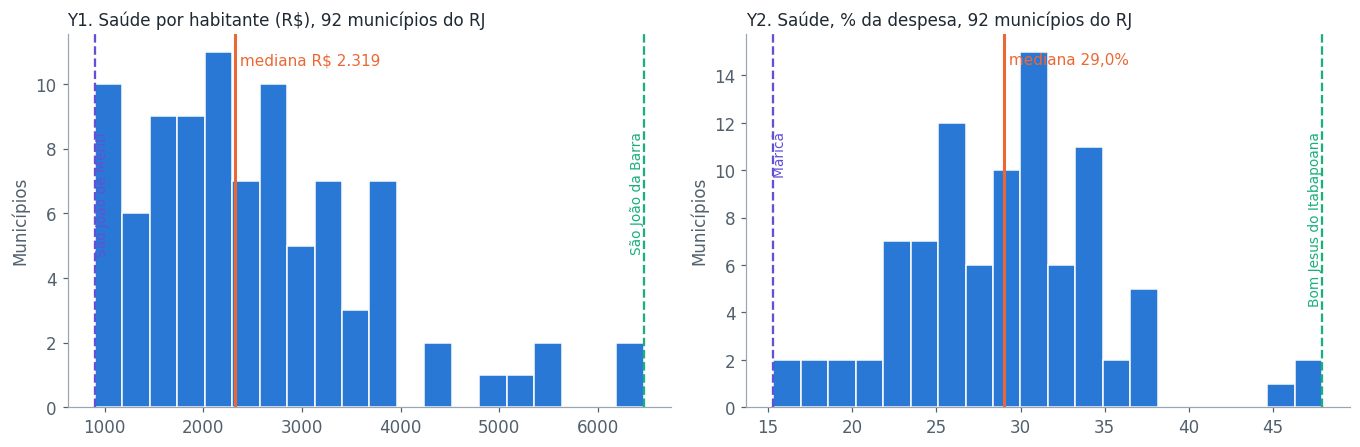

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(12.5, 4.2))
for ax, col, titulo, fmt in ((eixos[0], "saude_por_hab", "Y1. Saúde por habitante (R$)", fmt_rs), (eixos[1], "saude_pct_despesa", "Y2. Saúde, % da despesa", fmt_pct)):
    s = mun[col]
    ax.hist(s, bins=20, color=AZUL, edgecolor="#fcfcfb")
    ax.axvline(s.median(), color=LARANJA, lw=2)
    ax.text(s.median(), ax.get_ylim()[1] * .95, f" mediana {fmt(s.median())}", color=LARANJA, fontsize=10, va="top")
    for i, cor in ((s.idxmin(), VIOLETA), (s.idxmax(), VERDE)):
        ax.axvline(s[i], color=cor, lw=1.5, ls="--")
        ax.text(s[i], ax.get_ylim()[1] * .75, mun.loc[i, "nome"] + " ", color=cor, fontsize=9, ha="right" if i == s.idxmax() else "left", rotation=90, va="top")
    ax.set_title(titulo + ", 92 municípios do RJ", loc="left", fontsize=11, color=TEXTO)
    ax.set_ylabel("Municípios")
plt.tight_layout()
plt.savefig(ARTEFATOS / "distribuicao_y_municipios.png", dpi=150, bbox_inches="tight")
plt.show()

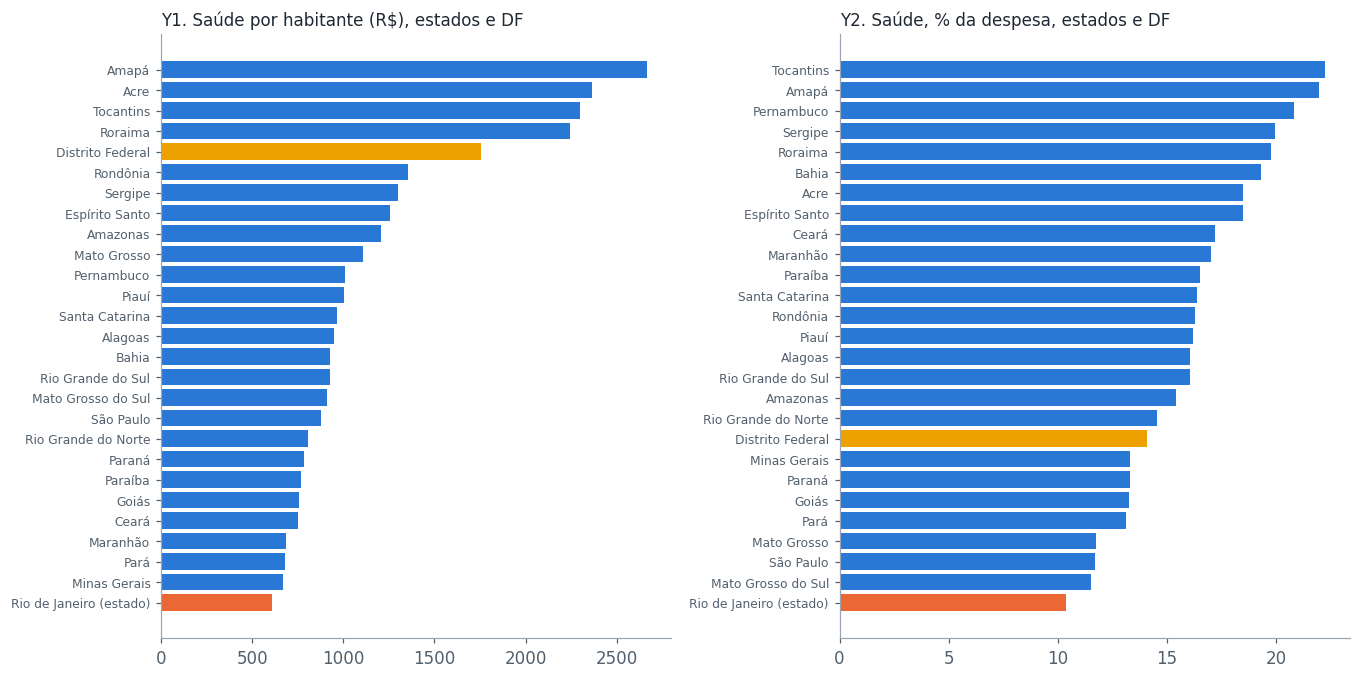

**O que vemos.** Nos municípios a distribuição é concentrada à esquerda e com cauda longa à direita (assimetria positiva): poucos municípios gastam muito por habitante. Nos estados, o RJ (laranja) é o de menor gasto por habitante e a menor fatia da despesa. O DF (âmbar) acumula funções de estado e de município, por isso é lido à parte.

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(12.5, 6.3))
for ax, col, titulo, fmt in ((eixos[0], "saude_por_hab", "Y1. Saúde por habitante (R$)", fmt_rs), (eixos[1], "saude_pct_despesa", "Y2. Saúde, % da despesa", fmt_pct)):
    e = est.sort_values(col)
    cores = [LARANJA if n.startswith("Rio de Janeiro") else (AMBAR if n == "Distrito Federal" else AZUL) for n in e.nome]
    ax.barh(e.nome, e[col], color=cores)
    ax.set_title(titulo + ", estados e DF", loc="left", fontsize=11, color=TEXTO)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(ARTEFATOS / "distribuicao_y_estados.png", dpi=150, bbox_inches="tight")
plt.show()
texto("**O que vemos.** Nos municípios a distribuição é concentrada à esquerda e com cauda longa à direita (assimetria positiva): poucos municípios gastam muito por habitante. "
      "Nos estados, o RJ (laranja) é o de menor gasto por habitante e a menor fatia da despesa. O DF (âmbar) acumula funções de estado e de município, por isso é lido à parte.")

## 7. Proporção vem com intervalo, e o intervalo certo (M7)

Uso o **intervalo de Wilson** (95%), que não falha com proporção pequena ou amostra pequena, e sempre mostro o **n**.

In [10]:
def prop(k, n, rotulo):
    lo, hi = wilson(k, n)
    leitura = f"1 a cada {br(n / k, 0)}" if k > 0 else "nenhum caso observado"
    return (rotulo, f"{k} de {n}", fmt_pct(k / n * 100), f"{fmt_pct(lo * 100)} a {fmt_pct(hi * 100)}", leitura)


m_ = mun.set_index("cod_ibge")
sm["pct_n"] = sm.pct.str.replace("%", "").str.replace(",", ".").astype(float)
linhas = [
    prop(int((sm.abaixo > 0).sum()), len(sm), "Municípios abaixo do mínimo de saúde da LC 141 (15%), SIOPS"),
    prop(int((mun.despesa_pct_receita > 115).sum()), len(mun), "Municípios com despesa acima de 115% da receita"),
    prop(int(mun.acima_prudencial.fillna(False).astype(bool).sum()), len(mun), "Municípios com pessoal do Executivo acima do limite prudencial declarado"),
    prop(int((mun.flag_especial != "").sum()), len(mun), "Municípios com dado marcado como em dúvida"),
    prop(int(mun.relatorio_simplificado.sum()), len(mun), "Municípios que entregam relatório simplificado"),
]
tabela_md(pd.DataFrame(linhas, columns=["Proporção", "k de n", "Valor", "Intervalo de Wilson 95%", "Leitura humana"]).set_index("Proporção"), indice="Proporção")
texto("**O que vemos.** Nenhum município aparece abaixo do mínimo de saúde, mas com 92 observações o intervalo vai de 0% a cerca de 4%: **não dá para afirmar que a verdadeira taxa é zero**, só que é baixa. "
      "Todas essas proporções são de dado declarado pelos entes.")

| Proporção | k de n | Valor | Intervalo de Wilson 95% | Leitura humana |
|---|---|---|---|---|
| Municípios abaixo do mínimo de saúde da LC 141 (15%), SIOPS | 0 de 92 | 0,0% | 0,0% a 4,0% | nenhum caso observado |
| Municípios com despesa acima de 115% da receita | 7 de 92 | 7,6% | 3,7% a 14,9% | 1 a cada 13 |
| Municípios com pessoal do Executivo acima do limite prudencial declarado | 22 de 92 | 23,9% | 16,4% a 33,6% | 1 a cada 4 |
| Municípios com dado marcado como em dúvida | 4 de 92 | 4,3% | 1,7% a 10,7% | 1 a cada 23 |
| Municípios que entregam relatório simplificado | 12 de 92 | 13,0% | 7,6% a 21,4% | 1 a cada 8 |

**O que vemos.** Nenhum município aparece abaixo do mínimo de saúde, mas com 92 observações o intervalo vai de 0% a cerca de 4%: **não dá para afirmar que a verdadeira taxa é zero**, só que é baixa. Todas essas proporções são de dado declarado pelos entes.

## 8. Regiões: taxa não soma (M17)

As regiões são as **8 Regiões de Governo do CEPERJ**, com a **capital à parte** (decisão do Matheus). A saúde por habitante de uma região é **a soma da saúde dividida pela soma da população**, e não a média das taxas dos municípios, que daria o mesmo peso a um município de 5 mil e a um de 800 mil habitantes. Mostro também a **mediana** dos municípios.

C:\Users\Augusto\AppData\Local\Temp\ipykernel_34308\1503878835.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reg = mun.groupby("regiao").apply(agrega).sort_values("Saúde por hab. (soma ÷ soma)", ascending=False)


| Região | Municípios | População | Saúde por hab. (soma ÷ soma) | Mediana dos municípios | Menor | Maior | Fatia da saúde (soma ÷ soma) |
|---|---|---|---|---|---|---|---|
| Costa Verde | 3 | 270.358 | R$ 3.629 | R$ 3.419 | Paraty R$ 3.204 | Angra dos Reis R$ 3.793 | 25,5% |
| Norte Fluminense | 9 | 983.045 | R$ 2.847 | R$ 2.689 | São Francisco de Itabapoana R$ 1.155 | São João da Barra R$ 6.465 | 29,4% |
| Noroeste Fluminense | 13 | 340.005 | R$ 2.743 | R$ 2.818 | Miracema R$ 1.737 | Bom Jesus do Itabapoana R$ 3.801 | 36,2% |
| Baixadas Litorâneas | 10 | 925.197 | R$ 2.419 | R$ 2.855 | São Pedro da Aldeia R$ 949 | Arraial do Cabo R$ 5.525 | 23,6% |
| Centro-Sul Fluminense | 11 | 301.669 | R$ 2.390 | R$ 2.835 | Paraíba do Sul R$ 1.559 | Vassouras R$ 3.861 | 29,0% |
| Médio Paraíba | 11 | 909.166 | R$ 2.062 | R$ 2.305 | Barra do Piraí R$ 1.274 | Porto Real R$ 4.478 | 30,8% |
| Serrana | 13 | 553.610 | R$ 1.662 | R$ 2.259 | Teresópolis R$ 1.217 | Macuco R$ 4.427 | 29,8% |
| Metropolitana (sem a capital) | 21 | 6.206.735 | R$ 1.570 | R$ 1.643 | São João de Meriti R$ 900 | Maricá R$ 5.188 | 26,9% |
| Capital (Rio de Janeiro) | 1 | 6.729.894 | R$ 1.136 | R$ 1.136 | Rio de Janeiro (capital) R$ 1.136 | Rio de Janeiro (capital) R$ 1.136 | 19,3% |

**O que vemos.** Se eu tirasse a média simples das taxas em vez de somar, o valor de uma região mudaria até R$ 673 por habitante (em Serrana). Por isso a soma é a medida da região. Esta é uma **descrição**, não um teste de diferença entre regiões (isso é do Analyze).

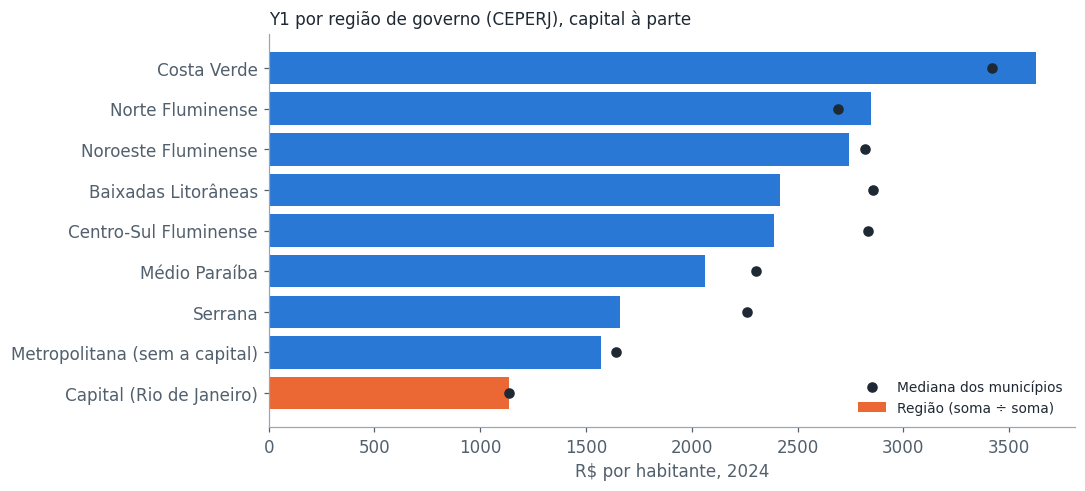

In [11]:
cmap = {norm(r.municipio): r.regiao for r in ceperj.itertuples()}
mun["regiao"] = mun.ente.map(lambda x: cmap[norm(x)])
mun.loc[mun.cod_ibge == "3304557", "regiao"] = "Capital (Rio de Janeiro)"
mun.loc[(mun.regiao == "Metropolitana"), "regiao"] = "Metropolitana (sem a capital)"
assert mun.regiao.notna().all()


def agrega(g):
    s = g.set_index("nome").saude_por_hab
    return pd.Series({"Municípios": len(g), "População": g.populacao.sum(), "Saúde por hab. (soma ÷ soma)": g.saude.sum() / g.populacao.sum(),
                      "Mediana dos municípios": s.median(), "Menor": s.idxmin() + " " + fmt_rs(s.min()), "Maior": s.idxmax() + " " + fmt_rs(s.max()),
                      "Fatia da saúde (soma ÷ soma)": g.saude.sum() / g.despesa_base_saude.sum() * 100})


reg = mun.groupby("regiao").apply(agrega).sort_values("Saúde por hab. (soma ÷ soma)", ascending=False)
tabela_md(reg, {"Municípios": fmt_int, "População": fmt_int, "Saúde por hab. (soma ÷ soma)": fmt_rs, "Mediana dos municípios": fmt_rs, "Fatia da saúde (soma ÷ soma)": fmt_pct}, indice="Região")
ingenuo = mun.groupby("regiao").saude_por_hab.mean()
dif = (ingenuo - reg["Saúde por hab. (soma ÷ soma)"]).abs()
texto(f"**O que vemos.** Se eu tirasse a média simples das taxas em vez de somar, o valor de uma região mudaria até {fmt_rs(dif.max())} por habitante (em {dif.idxmax()}). "
      "Por isso a soma é a medida da região. Esta é uma **descrição**, não um teste de diferença entre regiões (isso é do Analyze).")

fig, ax = plt.subplots(figsize=(10, 4.6))
r = reg.sort_values("Saúde por hab. (soma ÷ soma)")
cores = [LARANJA if i.startswith("Capital") else AZUL for i in r.index]
ax.barh(r.index, r["Saúde por hab. (soma ÷ soma)"], color=cores, label="Região (soma ÷ soma)")
ax.scatter(r["Mediana dos municípios"], r.index, color=TEXTO, zorder=3, s=35, label="Mediana dos municípios")
ax.set_xlabel("R$ por habitante, 2024"); ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("Y1 por região de governo (CEPERJ), capital à parte", loc="left", fontsize=11, color=TEXTO)
plt.tight_layout(); plt.savefig(ARTEFATOS / "y1_por_regiao.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Poder estatístico antes de estratificar (M19)

Antes de comparar regiões, calculo o **efeito mínimo detectável**: a menor diferença de gasto por habitante, entre uma região e o resto dos municípios, que o n disponível conseguiria enxergar (nível de 5%, poder de 80%). Trabalho em escala de logaritmo, porque o gasto por habitante é assimétrico.

**Regra que escolhi:** recorte com efeito mínimo detectável de **50% ou mais** não sustenta conclusão sobre diferença (a diferença teria de ser enorme para aparecer).

In [12]:
fora_cap = mun[mun.regiao != "Capital (Rio de Janeiro)"]
s_log = np.log(fora_cap.saude_por_hab).std()
z = 1.96 + 0.8416
linhas = []
for nome, g in fora_cap.groupby("regiao"):
    n1, n2 = len(g), len(fora_cap) - len(g)
    efeito = np.exp(z * s_log * np.sqrt(1 / n1 + 1 / n2))
    linhas.append((nome, n1, (efeito - 1) * 100, "Sustenta" if (efeito - 1) < 0.5 else "NÃO sustenta"))
pod = pd.DataFrame(linhas, columns=["Região", "n", "Efeito mínimo detectável (%)", "Conclusão sobre diferença"]).set_index("Região").sort_values("n")
tabela_md(pod, {"n": fmt_int, "Efeito mínimo detectável (%)": fmt_pct}, indice="Região")
texto(f"**O que vemos.** O desvio-padrão do log do gasto por habitante é {br(s_log, 2)}. "
      f"Regiões com poucos municípios (Costa Verde tem {int(pod.loc['Costa Verde', 'n'])}) só mostrariam uma diferença muito grande; "
      f"**{int((pod['Conclusão sobre diferença'] == 'NÃO sustenta').sum())} das {len(pod)} regiões não sustentam conclusão sobre diferença** com esta regra. "
      "A **capital** (n = 1) só pode ser descrita, nunca testada, e é sempre mostrada à parte.")

| Região | n | Efeito mínimo detectável (%) | Conclusão sobre diferença |
|---|---|---|---|
| Costa Verde | 3 | 111,5% | NÃO sustenta |
| Norte Fluminense | 9 | 56,5% | NÃO sustenta |
| Baixadas Litorâneas | 10 | 53,4% | NÃO sustenta |
| Centro-Sul Fluminense | 11 | 50,7% | NÃO sustenta |
| Médio Paraíba | 11 | 50,7% | NÃO sustenta |
| Noroeste Fluminense | 13 | 46,6% | Sustenta |
| Serrana | 13 | 46,6% | Sustenta |
| Metropolitana (sem a capital) | 21 | 37,4% | Sustenta |

**O que vemos.** O desvio-padrão do log do gasto por habitante é 0,46. Regiões com poucos municípios (Costa Verde tem 3) só mostrariam uma diferença muito grande; **5 das 8 regiões não sustentam conclusão sobre diferença** com esta regra. A **capital** (n = 1) só pode ser descrita, nunca testada, e é sempre mostrada à parte.

## 10. O que não se aplica neste projeto

| Regra | Por que não se aplica |
|---|---|
| M8 a M15 (estabilidade, cartas de controle, sobredispersão, sazonalidade, autocorrelação, imaturidade do fim da série) | **O projeto tem um só ano (2024) e um corte transversal.** Sem eixo temporal, a estabilidade não pode ser avaliada, e isso impede concluir se a diferença entre entes é estável ao longo do tempo. |
| M16 (capabilidade e nível sigma) | Não há meta numérica (a declaração do problema não define uma), e o processo não é um processo repetido com especificação. |
| M20 (deflacionar) | Um só ano: não há comparação entre períodos nem entre moedas. |
| M21 (quebra de série) | Idem: sem série, sem quebra. |

## 11. Baseline congelado (M22)

Gravo o ponto de partida dos dois Y num arquivo que **não será mais editado**: métrica, valor, intervalo, n, janela, filtros e data. Correção futura é adendo datado, nunca edição.

In [13]:
from datetime import date
import hashlib

def linha(grupo, df, col, nome, fmt, filtro):
    s = df[col].dropna()
    q1, med, q3 = s.quantile([.25, .5, .75])
    return {"metrica": nome, "grupo": grupo, "filtro": filtro, "n": len(s), "mediana": med, "q1": q1, "q3": q3,
            "minimo": s.min(), "ente_minimo": df.loc[s.idxmin(), "nome"], "maximo": s.max(), "ente_maximo": df.loc[s.idxmax(), "nome"],
            "media": s.mean()}

est_sem_df = est[est.nome != "Distrito Federal"]
mun_sem = mun[mun.flag_especial == ""]
mun_sem_simpl = mun[(mun.flag_especial == "") & (~mun.relatorio_simplificado)]
linhas = []
for col, nome, fmt in (("saude_por_hab", "Y1. Saúde por habitante (R$)", fmt_rs), ("saude_pct_despesa", "Y2. Saúde, % da despesa (%)", fmt_pct)):
    linhas += [linha("Municípios do RJ", mun, col, nome, fmt, "todos os 92"),
               linha("Municípios do RJ", mun_sem, col, nome, fmt, "sem os 4 marcados"),
               linha("Municípios do RJ", mun_sem_simpl, col, nome, fmt, "sem os marcados e sem os simplificados"),
               linha("Estados e DF", est, col, nome, fmt, "todos os 27 (com o DF)"),
               linha("Estados e DF", est_sem_df, col, nome, fmt, "sem o DF (26 estados)")]
base = pd.DataFrame(linhas)
base["janela"] = "Exercício de 2024 (RREO 6º bimestre; RGF 3º quadrimestre ou 2º semestre)"
base["populacao_usada"] = "Estimativa 2024 do IBGE (SIDRA, tabela 6579)"
base["congelado_em"] = date.today().isoformat()
base["fonte"] = "dados_tratados/indicadores_2024.csv"
base["saude_busios"] = "DCA Anexo I-E, função 10 (checagem A2)"
destino = RAIZ / "fases" / "fase-2b-measure-baseline" / "artefatos" / "baseline_measure_2024.csv"
destino.parent.mkdir(parents=True, exist_ok=True)
base.to_csv(destino, index=False, encoding="utf-8-sig")
sha = hashlib.sha256(destino.read_bytes()).hexdigest()
(destino.parent / "baseline_measure_2024.sha256").write_text(f"{sha}  baseline_measure_2024.csv\n", encoding="utf-8")

exib = base.copy()
for c in ("mediana", "q1", "q3", "minimo", "maximo", "media"):
    exib[c] = [fmt_rs(v) if "R$" in m else fmt_pct(v) for v, m in zip(exib[c], exib.metrica)]
tabela_md(exib[["metrica", "grupo", "filtro", "n", "mediana", "q1", "q3", "minimo", "ente_minimo", "maximo", "ente_maximo"]].set_index("metrica"),
          {"n": fmt_int}, indice="Métrica")
texto(f"**Baseline gravado** em `fases/fase-2b-measure-baseline/artefatos/baseline_measure_2024.csv` (SHA-256 `{sha[:16]}…`). **Não editar.**")

| Métrica | grupo | filtro | n | mediana | q1 | q3 | minimo | ente_minimo | maximo | ente_maximo |
|---|---|---|---|---|---|---|---|---|---|---|
| Y1. Saúde por habitante (R$) | Municípios do RJ | todos os 92 | 92 | R$ 2.319 | R$ 1.689 | R$ 3.217 | R$ 900 | São João de Meriti | R$ 6.465 | São João da Barra |
| Y1. Saúde por habitante (R$) | Municípios do RJ | sem os 4 marcados | 88 | R$ 2.282 | R$ 1.658 | R$ 3.217 | R$ 900 | São João de Meriti | R$ 6.465 | São João da Barra |
| Y1. Saúde por habitante (R$) | Municípios do RJ | sem os marcados e sem os simplificados | 76 | R$ 2.210 | R$ 1.554 | R$ 3.052 | R$ 900 | São João de Meriti | R$ 6.465 | São João da Barra |
| Y1. Saúde por habitante (R$) | Estados e DF | todos os 27 (com o DF) | 27 | R$ 946 | R$ 775 | R$ 1.277 | R$ 606 | Rio de Janeiro (estado) | R$ 2.666 | Amapá |
| Y1. Saúde por habitante (R$) | Estados e DF | sem o DF (26 estados) | 26 | R$ 937 | R$ 770 | R$ 1.245 | R$ 606 | Rio de Janeiro (estado) | R$ 2.666 | Amapá |
| Y2. Saúde, % da despesa (%) | Municípios do RJ | todos os 92 | 92 | 29,0% | 25,2% | 32,6% | 15,3% | Maricá | 47,9% | Bom Jesus do Itabapoana |
| Y2. Saúde, % da despesa (%) | Municípios do RJ | sem os 4 marcados | 88 | 29,3% | 25,2% | 32,6% | 15,3% | Maricá | 47,9% | Bom Jesus do Itabapoana |
| Y2. Saúde, % da despesa (%) | Municípios do RJ | sem os marcados e sem os simplificados | 76 | 28,5% | 24,9% | 31,6% | 15,3% | Maricá | 47,9% | Bom Jesus do Itabapoana |
| Y2. Saúde, % da despesa (%) | Estados e DF | todos os 27 (com o DF) | 27 | 16,2% | 13,3% | 18,5% | 10,4% | Rio de Janeiro (estado) | 22,3% | Tocantins |
| Y2. Saúde, % da despesa (%) | Estados e DF | sem o DF (26 estados) | 26 | 16,2% | 13,3% | 18,5% | 10,4% | Rio de Janeiro (estado) | 22,3% | Tocantins |

**Baseline gravado** em `fases/fase-2b-measure-baseline/artefatos/baseline_measure_2024.csv` (SHA-256 `8900dedcbbd019f2…`). **Não editar.**

## 12. O que mais o Measure fixou: limites legais e regiões, em colunas novas

Estas colunas não alteram os indicadores da EDA: ficam num arquivo novo, `indicadores_measure_2024.csv`, para o Analyze usar.

In [14]:
m2 = ind.copy()
m2["regiao_ceperj"] = m2.apply(lambda r: ("Capital (Rio de Janeiro)" if r.cod_ibge == "3304557" else cmap.get(norm(r.ente))) if r.esfera == "M" else None, axis=1)
m2.loc[m2.regiao_ceperj == "Metropolitana", "regiao_ceperj"] = "Metropolitana (sem a capital)"
m2["limite_legal_dcl_pct"] = np.where(m2.esfera == "M", 120.0, 200.0)          # Resolução do Senado 40/2001, art. 3º
m2["dcl_acima_limite_legal"] = m2.dcl_pct_rcl > m2.limite_legal_dcl_pct
m2["limite_legal_exec_pct"] = np.where(m2.esfera == "M", 54.0, 49.0)           # LRF, art. 20, II, c e III, b
m2["exec_acima_limite_legal"] = m2.pessoal_pct_rcl > m2.limite_legal_exec_pct
m2["limite_declarado_difere_da_lei"] = (m2.limite_max_pct - m2.limite_legal_exec_pct).abs() > 0.05
m2.to_csv(TRAT / "indicadores_measure_2024.csv", index=False, encoding="utf-8-sig")

n_dcl = m2[m2.dcl_acima_limite_legal]
n_exec = m2[m2.exec_acima_limite_legal]
dif_lim = m2[m2.limite_declarado_difere_da_lei]
texto(f"Gravado `dados_tratados/indicadores_measure_2024.csv` ({len(m2)} entes, {m2.shape[1]} colunas).\n\n"
      f"- **Dívida líquida acima do limite legal (2× a RCL nos estados e DF, 1,2× nos municípios):** {len(n_dcl)} ente(s): {', '.join(n_dcl.nome) or 'nenhum'}.\n"
      f"- **Pessoal do Executivo acima do limite legal (49% estados e DF, 54% municípios):** {len(n_exec)} ente(s), dos quais {int((n_exec.flag_especial != '').sum())} com a marca de dado em dúvida ({', '.join(n_exec[n_exec.flag_especial != ''].nome) or 'nenhum'}). Esses são lidos com a ressalva da RCL atípica.\n"
      f"- **Limite de pessoal do Executivo que o ente declara e que difere da lei:** {len(dif_lim)} ente(s): {', '.join(dif_lim.nome)}.")

Gravado `dados_tratados/indicadores_measure_2024.csv` (119 entes, 55 colunas).

- **Dívida líquida acima do limite legal (2× a RCL nos estados e DF, 1,2× nos municípios):** 1 ente(s): Rio de Janeiro (estado).
- **Pessoal do Executivo acima do limite legal (49% estados e DF, 54% municípios):** 12 ente(s), dos quais 3 com a marca de dado em dúvida (Areal, Itaperuna, Miracema). Esses são lidos com a ressalva da RCL atípica.
- **Limite de pessoal do Executivo que o ente declara e que difere da lei:** 4 ente(s): Pará, Bahia, Goiás, Maricá.

## 13. Registro de escolhas

| Escolha | O que usei | O que mais considerei | Por que esta | Evidência | Regra |
|---|---|---|---|---|---|
| Intervalo de proporção | Wilson 95% | Wald (convencional) | Com 0 casos em 92, o Wald daria intervalo zero, que não é verdade | Seção 7 | M7 |
| Agregado de região | Soma do numerador ÷ soma do denominador | Média das taxas dos municípios (convencional) | A média dá o mesmo peso a município pequeno e grande e não corresponde a nenhuma população | Seção 8 | M17 |
| Centro e dispersão | Mediana e quartis | Média e desvio-padrão (convencional) | A distribuição dos municípios é assimétrica, com cauda longa à direita | Seção 6 | M6 |
| Atípicos | Marcar e mostrar com e sem | Remover (convencional) | Remover um ente sem prova de erro é garimpo; a conclusão não muda com ou sem | Seção 5.2 | M5 |
| População | Estimativa 2024 do IBGE | População do campo do Siconfi (convencional no projeto) | O campo do Siconfi não bate com nenhum ano do IBGE; o IBGE é oficial e do ano da despesa | docs/07, B1 | M4 |
| Saúde de Búzios | Valor da DCA | Valor do RREO Anexo 02 | O Anexo 02 dele é incoerente por dentro; a DCA concorda com o Anexo 01 e com o SIOPS | docs/07, A2 | M2 |
| Efeito mínimo detectável | Escala de log, nível 5%, poder 80%, corte em 50% | Teste de permutação; corte em 30% | Escala simples e explicável; o corte de 50% é uma escolha minha, dita acima | Seção 9 | M19 |
| Limites legais | Resolução do Senado 40/2001 e LRF arts. 19, 20 e 22 | Limites que o ente declara (convencional no projeto) | Alguns entes declaram limites que não batem com a lei | docs/04, A1 e C1 | M2 |